# 3. Modélisation

**Entrée :** `data/batiments_cible.csv` (notebook 2).

### Import des modules 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

In [2]:
df = pd.read_csv("data/batiments_cible.csv")
cible = "SiteEnergyUse(kBtu)"
print(df.shape)

(1481, 21)


### Feature Engineering

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

#### 1. Période de construction

L'année exacte compte moins que l'époque (normes, isolation). On découpe en 4 périodes de taille comparable.

In [3]:
def periode(annee):
    if annee < 1950:
        return "avant 1950"
    elif annee < 1980:
        return "1950-1979"
    elif annee < 2000:
        return "1980-1999"
    else:
        return "2000 et après"

df["Periode"] = df["YearBuilt"].apply(periode)
df["Periode"].value_counts()

Periode
1950-1979        494
avant 1950       475
1980-1999        288
2000 et après    224
Name: count, dtype: int64

#### 2. Utilise du gaz / de la vapeur

Les quantités de gaz et de vapeur font partie de la cible : les garder serait une **fuite de données**. Savoir *si* le bâtiment est raccordé est en revanche connu sans compteur. On garde donc oui (1) / non (0).

In [4]:
# 1 = oui, 0 = non
df["UtiliseGaz"] = df["NaturalGas(kBtu)"].apply(lambda x: 1 if x > 0 else 0)
df["UtiliseVapeur"] = df["SteamUse(kBtu)"].apply(lambda x: 1 if x > 0 else 0)

print("part qui utilise du gaz :", round(df["UtiliseGaz"].mean(), 2))
print("part qui utilise de la vapeur :", round(df["UtiliseVapeur"].mean(), 2))

part qui utilise du gaz : 0.71
part qui utilise de la vapeur : 0.07


#### 3. Part de la surface en parking

Un parking consomme peu : à surface égale, plus de parking devrait vouloir dire moins de consommation.

In [5]:
df["PartParking"] = df["PropertyGFAParking"] / df["PropertyGFATotal"]
df["PartParking"].describe()

count    1481.000000
mean        0.066472
std         0.145105
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         0.895023
Name: PartParking, dtype: float64

#### 4. Nombre d'usages

On compte les usages renseignés (1, 2 ou 3) : un bâtiment multi-usages a souvent des besoins plus variés.

In [6]:
df["NbUsages"] = 1 + df["SecondLargestPropertyUseType"].notna().astype(int) + df["ThirdLargestPropertyUseType"].notna().astype(int)
df["NbUsages"].value_counts()

NbUsages
1    676
2    478
3    327
Name: count, dtype: int64

#### 5. Colonnes retirées

- `YearBuilt` : remplacée par `Periode`.
- Les colonnes d'énergie brutes : fuite de données, remplacées par `UtiliseGaz` et `UtiliseVapeur`.
- `ENERGYSTARScore` : absent pour 35 % des bâtiments et calculé à partir de la consommation. Laissé de côté pour l'instant.

In [7]:
colonnes_a_retirer = [
    "YearBuilt",
    "Electricity(kWh)",
    "Electricity(kBtu)",
    "NaturalGas(therms)",
    "NaturalGas(kBtu)",
    "SteamUse(kBtu)",
    "ENERGYSTARScore",
]
df = df.drop(columns=colonnes_a_retirer)
print(df.shape)
df.head()

(1481, 19)


,PrimaryPropertyType,Neighborhood,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),Periode,UtiliseGaz,UtiliseVapeur,PartParking,NbUsages
0,Hotel,DOWNTOWN,1.0,12,88434,0,88434,Hotel,88434.0,NaN,0.0,NaN,0.0,7226362.5,avant 1950,1,1,0.000000,1
1,Hotel,DOWNTOWN,1.0,11,103566,15064,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,8387933.0,1980-1999,1,0,0.145453,3
2,Hotel,DOWNTOWN,1.0,41,956110,196718,759392,Hotel,756493.0,NaN,0.0,NaN,0.0,72587024.0,1950-1979,1,1,0.205748,1
3,Hotel,DOWNTOWN,1.0,10,61320,0,61320,Hotel,61320.0,NaN,0.0,NaN,0.0,6794584.0,avant 1950,1,1,0.000000,1
4,Hotel,DOWNTOWN,1.0,18,175580,62000,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,14172606.0,1980-1999,1,0,0.353115,3


### Préparation des features pour la modélisation

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

#### 1. Distribution de la cible

La distribution brute est déjà tracée dans le notebook 2 : elle est très étalée à droite (quelques très gros bâtiments). On passe donc la cible en **log10**, sinon ces gros bâtiments écraseraient l'apprentissage.

asymétrie brute : 10.77
asymétrie en log10 : 0.36


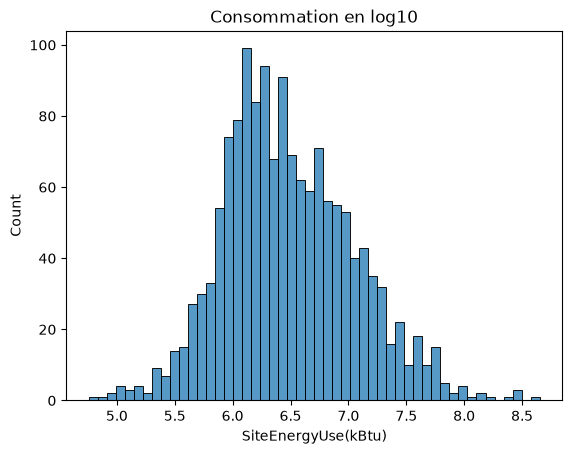

In [8]:
# cible en log10 (6 = 1 million de kBtu)
y = np.log10(df[cible])

print("asymétrie brute :", round(df[cible].skew(), 2))
print("asymétrie en log10 :", round(y.skew(), 2))

sns.histplot(y, bins=50)
plt.title("Consommation en log10")
plt.show()

**Outliers :** en log10, seuls 11 bâtiments sortent des moustaches (entrepôts, garde-meubles qui consomment très peu…). Ce sont des cas réels, pas des erreurs de saisie : je les garde.

#### 2. Matrice de corrélation

Deux colonnes très corrélées (au-dessus de 0,9) apportent presque la même information : on n'en garde qu'une.

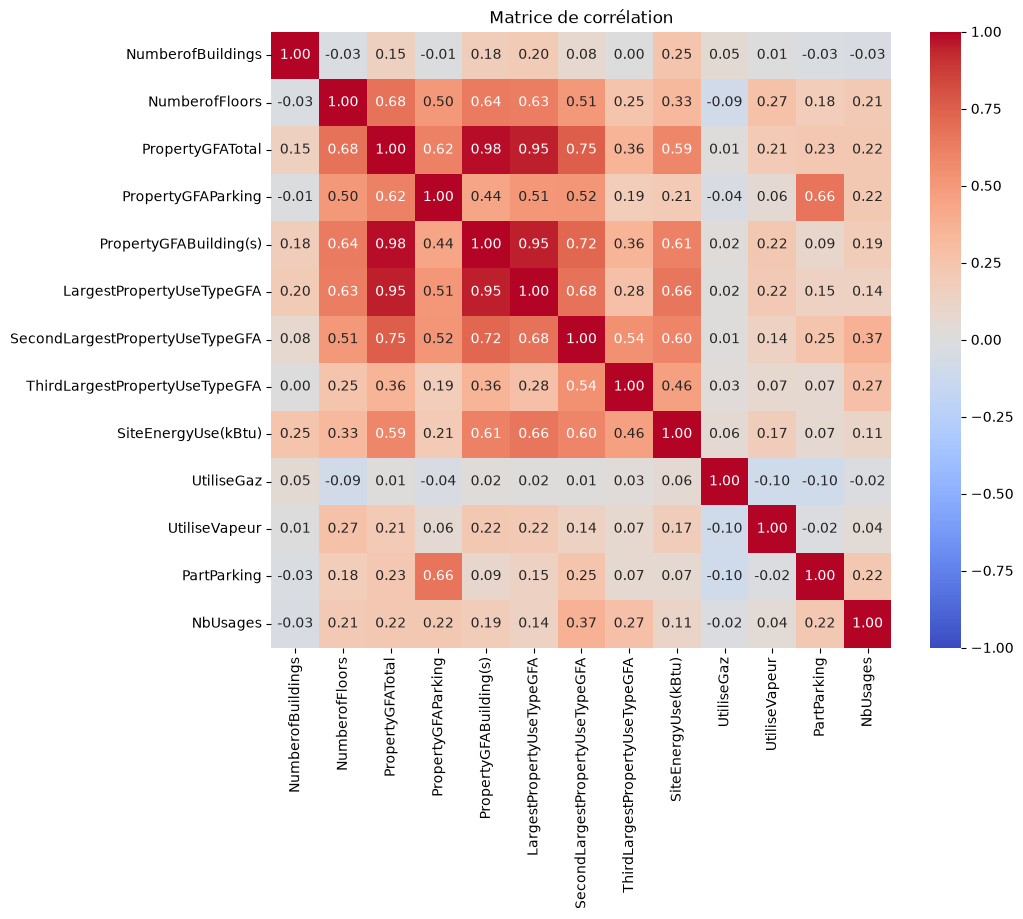

In [9]:
# corrélation de Pearson entre les colonnes numériques (cible comprise)
corr = df.select_dtypes("number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.show()

**Ce que je vois :**
- `PropertyGFATotal`, `PropertyGFABuilding(s)` et `LargestPropertyUseTypeGFA` sont corrélées entre 0,95 et 0,98 : ce sont presque la même surface mesurée trois fois.
- Les autres paires restent sous 0,8 (par exemple le nombre d'étages et la surface totale : 0,68).

➡️ Je garde `PropertyGFATotal` : c'est la surface la plus simple à expliquer, et `PartParking` est calculée à partir d'elle.

In [10]:
df = df.drop(columns=["PropertyGFABuilding(s)", "LargestPropertyUseTypeGFA"])
print(df.shape)

(1481, 17)


### Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [11]:
# CODE COMPARAISON DES MODELES

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

In [12]:
# CODE OPTIMISATION ET INTERPRETATION DU MODELE